**Atelier 2 - CNN et VIT**

In [ ]:
# Environnement GPU
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé :", device)
if device.type == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))

Device utilisé : cuda
GPU : Tesla T4


In [ ]:
# Charger MNIST
from torchvision import datasets, transforms   # torchvision apporte ce qui est spécifique à la vision : datasets, transformations d'images et modèles pré-entraîné
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_set = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_set  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_set, batch_size=64,   shuffle=True)
test_loader  = DataLoader(test_set,  batch_size=1000, shuffle=False)

print("Train :", len(train_set), "images | Test :", len(test_set), "images")
images, labels = next(iter(train_loader))
print("Forme d'un batch :", images.shape)   # 64 images, 1 canal, 28×28 pixels

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.09MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 133kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.2MB/s]

Train : 60000 images | Test : 10000 images
Forme d'un batch : torch.Size([64, 1, 28, 28])


In [ ]:
# Définir le CNN
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool  = nn.MaxPool2d(kernel_size=2, stride=2)
        self.dropout = nn.Dropout(0.25)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # [B,1,28,28] -> [B,32,14,14]
        x = self.pool(F.relu(self.conv2(x)))   # -> [B,64,7,7]
        x = torch.flatten(x, 1)                # -> [B,3136]
        x = self.dropout(F.relu(self.fc1(x)))  # -> [B,128]
        return self.fc2(x)                     # -> [B,10]

model = CNN().to(device)
print(model)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Paramètres : 421642


In [ ]:
out = model(images.to(device))
print(out.shape)  # attendu : torch.Size([64, 10])

torch.Size([64, 10])


**Entraîner et évaluer le CNN**

In [ ]:
# Loss, optimiseur et fonction d'entraînement
import time
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()   # remet les gradients à zéro, car PyTorch les accumule par défaut
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
    return running_loss / len(loader.dataset)

In [ ]:
# Fonction d'évaluation
def evaluate(model, loader, criterion):
    model.eval()  # désactive le dropout : à l'évaluation, on veut utiliser tous les neurones
    running_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            running_loss += criterion(outputs, labels).item() * inputs.size(0)

            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    loss = running_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average="macro")
    return loss, acc, f1

In [ ]:
# Lancer l'entraînement avec chronométrage
EPOCHS = 5 # un passage complet sur les 60 000 images. On en fait 5.
results = {}

train_time = 0.0
for epoch in range(EPOCHS):
    t0 = time.time()
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer)
    if device.type == "cuda":
        torch.cuda.synchronize()
    train_time += time.time() - t0

    test_loss, acc, f1 = evaluate(model, test_loader, criterion)
    print(f"Epoch {epoch+1}/{EPOCHS} | train loss {train_loss:.4f} | "
          f"test loss {test_loss:.4f} | acc {acc:.4f} | F1 {f1:.4f}")

print(f"Temps d'entraînement : {train_time:.1f} s")
results["CNN"] = {"loss": test_loss, "accuracy": acc, "f1": f1, "time": train_time}


Epoch 1/5 | train loss 0.1520 | test loss 0.0400 | acc 0.9858 | F1 0.9857
Epoch 2/5 | train loss 0.0536 | test loss 0.0324 | acc 0.9890 | F1 0.9890
Epoch 3/5 | train loss 0.0387 | test loss 0.0320 | acc 0.9894 | F1 0.9892
Epoch 4/5 | train loss 0.0300 | test loss 0.0253 | acc 0.9921 | F1 0.9920
Epoch 5/5 | train loss 0.0242 | test loss 0.0263 | acc 0.9918 | F1 0.9917
Temps d'entraînement : 76.6 s


**Résultat du CNN (5 epochs)** : accuracy 99,18 %, F1 0,9917, loss de test 0,0263, temps d'entraînement 76,6 s.

- Le modèle apprend vite : 98,6 % d'accuracy dès le premier epoch, 99,2 % à la fin, et la loss d'entraînement baisse à chaque epoch.
- L'accuracy et le F1 sont presque identiques car MNIST est équilibré (environ 6 000 images par chiffre).
- Aux premiers epochs, la loss d'entraînement est plus haute que celle de test : elle est moyennée pendant l'epoch avec le dropout actif, alors que la loss de test est mesurée en fin d'epoch sans dropout. Ce n'est pas du surapprentissage.

**Faster R-CNN**

In [ ]:
# Dataset adapté à la détection
import numpy as np
from torch.utils.data import Dataset, Subset
from torchvision import transforms

class MNISTDetection(Dataset):
    def __init__(self, train):
        self.base = datasets.MNIST(root="./data", train=train, download=True,
                                   transform=transforms.ToTensor())

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, digit = self.base[idx]                 # img : [1,28,28] entre 0 et 1
        ys, xs = torch.where(img[0] > 0.1)          # pixels "allumés"
        box = torch.tensor([[xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]],
                           dtype=torch.float32)
        img3 = img.repeat(3, 1, 1)                  # [1,28,28] -> [3,28,28]
        target = {"boxes": box, "labels": torch.tensor([digit + 1])}
        return img3, target

In [ ]:
# Sous-ensemble et DataLoaders
TRAIN_N, TEST_N = 10000, 2000

det_train = Subset(MNISTDetection(train=True),  range(TRAIN_N))
det_test  = Subset(MNISTDetection(train=False), range(TEST_N))

def collate(batch):
    return tuple(zip(*batch))

det_train_loader = DataLoader(det_train, batch_size=16, shuffle=True,  collate_fn=collate)
det_test_loader  = DataLoader(det_test,  batch_size=32, shuffle=False, collate_fn=collate)

In [ ]:
# Charger le modèle
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

frcnn = fasterrcnn_resnet50_fpn(weights="DEFAULT", min_size=128, max_size=128)
in_features = frcnn.roi_heads.box_predictor.cls_score.in_features
frcnn.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes=11)
frcnn = frcnn.to(device)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 177MB/s]


In [ ]:
# Entraînement
params = [p for p in frcnn.parameters() if p.requires_grad]
opt_det = optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)

FR_EPOCHS = 2
fr_train_time = 0.0

for epoch in range(FR_EPOCHS):
    frcnn.train()
    t0 = time.time()
    total = 0.0
    for images, targets in det_train_loader:
        images  = [im.to(device) for im in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = frcnn(images, targets)
        loss = sum(loss_dict.values())

        opt_det.zero_grad()
        loss.backward()
        opt_det.step()
        total += loss.item()

    torch.cuda.synchronize()
    fr_train_time += time.time() - t0
    print(f"Epoch {epoch+1}/{FR_EPOCHS} | loss {total/len(det_train_loader):.4f}")

print(f"Temps d'entraînement Faster R-CNN : {fr_train_time:.1f} s")

Epoch 1/2 | loss 0.1367
Epoch 2/2 | loss 0.0412
Temps d'entraînement Faster R-CNN : 581.1 s


In [ ]:
# Evaluation
@torch.no_grad()
def evaluate_frcnn(model, loader):
    # 1) loss de test (le modèle doit être en mode train pour la renvoyer)
    model.train()
    total_loss, n = 0.0, 0
    for images, targets in loader:
        images  = [im.to(device) for im in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        total_loss += sum(model(images, targets).values()).item() * len(images)
        n += len(images)

    # 2) prédictions
    model.eval()
    preds, labels = [], []
    for images, targets in loader:
        outputs = model([im.to(device) for im in images])
        for out, t in zip(outputs, targets):
            pred = out["labels"][0].item() - 1 if len(out["labels"]) > 0 else -1
            preds.append(pred)
            labels.append(t["labels"][0].item() - 1)

    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average="macro", labels=list(range(10)))
    return total_loss / n, acc, f1

fr_loss, fr_acc, fr_f1 = evaluate_frcnn(frcnn, det_test_loader)
print(f"Faster R-CNN | loss {fr_loss:.4f} | acc {fr_acc:.4f} | F1 {fr_f1:.4f}")
results["Faster R-CNN"] = {"loss": fr_loss, "accuracy": fr_acc, "f1": fr_f1, "time": fr_train_time}

Faster R-CNN | loss 0.0350 | acc 0.9865 | F1 0.9866


**Interprétation – Faster R-CNN.** MNIST ne contient pas de boîtes englobantes : nous en avons construit une autour de chaque chiffre (plus petit rectangle contenant les pixels allumés) et utilisé la classe de la détection la plus confiante comme prédiction. Entraîné sur 10 000 images (2 epochs) et testé sur 2 000, le modèle atteint 98,65 % d'accuracy (F1 0,9866), mais l'entraînement dure 581 s, soit environ 7,6 fois plus que le CNN. Faster R-CNN est un détecteur d'objets : pour classer un seul chiffre par image, il est surdimensionné. Sa loss (somme des pertes du RPN et de la tête de détection) n'est pas comparable à l'entropie croisée du CNN : seules l'accuracy et le F1 le sont. Il a aussi vu moins de données, ce qui rend la comparaison moins équitable.

**Fine-tuning de VGG16 et AlexNet**

In [ ]:
# Adapter l'entrée
class Adapter(nn.Module):
    def __init__(self, net, size=64):
        super().__init__()
        self.net = net
        self.size = size

    def forward(self, x):
        x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)
        x = x.repeat(1, 3, 1, 1)
        return self.net(x)

In [ ]:
# Construire le modèle
from torchvision import models

def build_pretrained(name):
    if name == "VGG16":
        net = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    else:
        net = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)

    for p in net.features.parameters():
        p.requires_grad = False

    net.classifier[6] = nn.Linear(4096, 10)
    model_ft = Adapter(net).to(device)

    total = sum(p.numel() for p in model_ft.parameters())
    trainable = sum(p.numel() for p in model_ft.parameters() if p.requires_grad)
    print(f"{name} | paramètres : {total:,} | entraînables : {trainable:,}")
    return model_ft

In [ ]:
# Entraîner et évaluer
def run_experiment(name, epochs=2, lr=1e-4):
    m = build_pretrained(name)
    opt = optim.Adam([p for p in m.parameters() if p.requires_grad], lr=lr)
    total_time = 0.0

    for epoch in range(epochs):
        t0 = time.time()
        train_loss = train_one_epoch(m, train_loader, criterion, opt)
        torch.cuda.synchronize()
        total_time += time.time() - t0

        loss, acc, f1 = evaluate(m, test_loader, criterion)
        print(f"{name} | Epoch {epoch+1}/{epochs} | train loss {train_loss:.4f} | "
              f"test loss {loss:.4f} | acc {acc:.4f} | F1 {f1:.4f}")

    print(f"Temps d'entraînement {name} : {total_time:.1f} s")
    results[name] = {"loss": loss, "accuracy": acc, "f1": f1, "time": total_time}
    return m

alexnet_model = run_experiment("AlexNet")
vgg_model = run_experiment("VGG16")


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 187MB/s]


AlexNet | paramètres : 57,044,810 | entraînables : 54,575,114
AlexNet | Epoch 1/2 | train loss 0.3164 | test loss 0.1894 | acc 0.9377 | F1 0.9364
AlexNet | Epoch 2/2 | train loss 0.1979 | test loss 0.1430 | acc 0.9512 | F1 0.9506
Temps d'entraînement AlexNet : 68.0 s
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 64.5MB/s]


VGG16 | paramètres : 134,301,514 | entraînables : 119,586,826
VGG16 | Epoch 1/2 | train loss 0.2316 | test loss 0.1098 | acc 0.9658 | F1 0.9654
VGG16 | Epoch 2/2 | train loss 0.1148 | test loss 0.0909 | acc 0.9710 | F1 0.9708
Temps d'entraînement VGG16 : 154.0 s


**Interprétation – Fine-tuning de VGG16 et AlexNet.** Seul le classifieur final a été entraîné (convolutions gelées, pré-entraînées sur ImageNet), pendant 2 epochs, avec des images agrandies à 64×64. VGG16 atteint 97,10 % (154 s) et AlexNet 95,12 % (68 s), soit moins que le CNN. Raisons probables : MNIST (28×28, niveaux de gris) est très différent d'ImageNet, les images agrandies sont floues et bien plus petites que les 224×224 prévus pour ces réseaux, et la loss baissait encore à la fin des 2 epochs. AlexNet est probablement plus pénalisé par la petite taille d'entrée. Le transfert d'apprentissage est surtout utile avec peu de données ou des images proches de celles du pré-entraînement.

In [ ]:
# Tableau comparatif
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(results).T[["accuracy", "f1", "loss", "time"]]
df.columns = ["Accuracy", "F1-score", "Loss", "Temps (s)"]
df = df.round(4)
display(df)
df.to_csv("resultats_partie1.csv")

,Accuracy,F1-score,Loss,Temps (s)
CNN,0.9918,0.9917,0.0263,76.6077
Faster R-CNN,0.9865,0.9866,0.0350,581.0918
AlexNet,0.9512,0.9506,0.1430,67.9946
VGG16,0.9710,0.9708,0.0909,154.0073


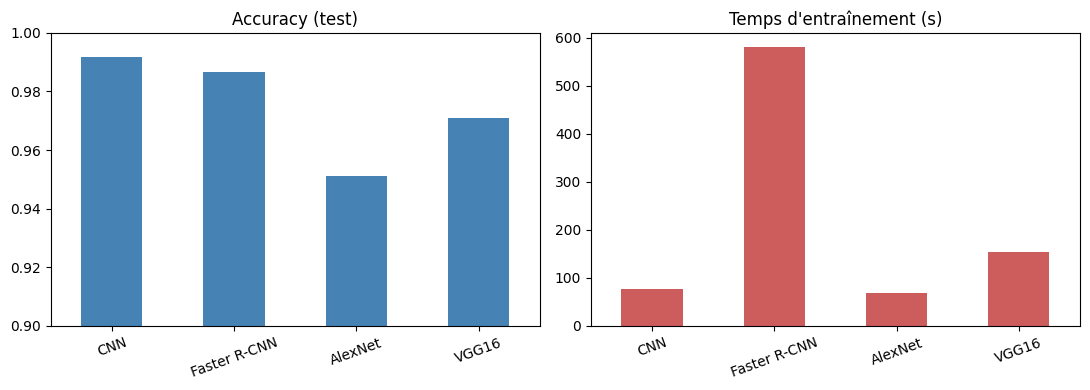

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["Accuracy"].plot.bar(ax=ax[0], ylim=(0.9, 1.0), title="Accuracy (test)", color="steelblue")
df["Temps (s)"].plot.bar(ax=ax[1], title="Temps d'entraînement (s)", color="indianred")
for a in ax:
    a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("comparaison_partie1.png", dpi=150)
plt.show()

**Conclusion de la partie 1**


Sur MNIST, le CNN entraîné de zéro obtient la meilleure accuracy (99,18 %) avec un temps d'entraînement faible (≈ 77 s) et seulement 421 642 paramètres. Faster R-CNN atteint 98,65 % mais coûte environ 7,6 fois plus de temps, pour une tâche de classification qui n'exige pas de localisation. VGG16 (97,10 %) et AlexNet (95,12 %), dont les convolutions étaient gelées et pré-entraînées sur ImageNet, restent en retrait : MNIST (28×28, niveaux de gris) est très éloigné de leur domaine d'origine. Le transfert d'apprentissage est surtout utile avec peu de données ou des images proches d'ImageNet.

**Partie 2 : Vision Transformer (ViT)**

In [ ]:
# Découper l'image en patchs
def patchify(images, n_patches):
    n, c, h, w = images.shape
    p = h // n_patches
    x = images.reshape(n, c, n_patches, p, n_patches, p)
    x = x.permute(0, 2, 4, 1, 3, 5)
    return x.reshape(n, n_patches ** 2, c * p * p)

# Test
x = torch.randn(7, 1, 28, 28)
print(patchify(x, 7).shape)   # attendu : torch.Size([7, 49, 16])

torch.Size([7, 49, 16])


In [ ]:
# Encodage positionnel
def get_positional_embeddings(sequence_length, d):
    pos = torch.arange(sequence_length, dtype=torch.float32).unsqueeze(1)   # [S, 1]
    j = torch.arange(d, dtype=torch.float32).unsqueeze(0)                    # [1, d]
    angles = pos / (10000 ** ((j - j % 2) / d))
    return torch.where(j % 2 == 0, torch.sin(angles), torch.cos(angles))

# Test
pe = get_positional_embeddings(50, 8)
print(pe.shape)    # attendu : torch.Size([50, 8])
print(pe[0])       # attendu : 0, 1, 0, 1, 0, 1, 0, 1

torch.Size([50, 8])
tensor([0., 1., 0., 1., 0., 1., 0., 1.])


In [ ]:
# Attention multi-têtes
class MyMSA(nn.Module):
    def __init__(self, d, n_heads=2):
        super().__init__()
        assert d % n_heads == 0, f"Impossible de diviser {d} en {n_heads} têtes"
        self.n_heads = n_heads
        self.d_head = d // n_heads
        self.q_mappings = nn.ModuleList([nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)])
        self.k_mappings = nn.ModuleList([nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)])
        self.v_mappings = nn.ModuleList([nn.Linear(self.d_head, self.d_head) for _ in range(n_heads)])

    def forward(self, x):                                   # x : [N, S, d]
        outs = []
        for h in range(self.n_heads):
            seq = x[:, :, h * self.d_head:(h + 1) * self.d_head]      # [N, S, d_head]
            q = self.q_mappings[h](seq)
            k = self.k_mappings[h](seq)
            v = self.v_mappings[h](seq)
            attn = torch.softmax(q @ k.transpose(1, 2) / self.d_head ** 0.5, dim=-1)   # [N, S, S]
            outs.append(attn @ v)                                      # [N, S, d_head]
        return torch.cat(outs, dim=-1)                                 # [N, S, d]

# Test
print(MyMSA(8, 2)(torch.randn(7, 50, 8)).shape)   # attendu : torch.Size([7, 50, 8])

torch.Size([7, 50, 8])


In [ ]:
# Bloc d'encodeur
class MyViTBlock(nn.Module):
    def __init__(self, hidden_d, n_heads, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(hidden_d)
        self.mhsa = MyMSA(hidden_d, n_heads)
        self.norm2 = nn.LayerNorm(hidden_d)
        self.mlp = nn.Sequential(
            nn.Linear(hidden_d, mlp_ratio * hidden_d),
            nn.GELU(),
            nn.Linear(mlp_ratio * hidden_d, hidden_d)
        )

    def forward(self, x):
        out = x + self.mhsa(self.norm1(x))
        out = out + self.mlp(self.norm2(out))
        return out

# Test
print(MyViTBlock(hidden_d=8, n_heads=2)(torch.randn(7, 50, 8)).shape)   # attendu : torch.Size([7, 50, 8])

torch.Size([7, 50, 8])


In [ ]:
# Le ViT complet
class MyViT(nn.Module):
    def __init__(self, chw=(1, 28, 28), n_patches=7, n_blocks=2, hidden_d=8, n_heads=2, out_d=10):
        super().__init__()
        c, h, w = chw
        assert h % n_patches == 0 and w % n_patches == 0, "Image non divisible en patchs"
        self.n_patches = n_patches
        self.input_d = c * (h // n_patches) * (w // n_patches)

        self.linear_mapper = nn.Linear(self.input_d, hidden_d)
        self.class_token = nn.Parameter(torch.rand(1, hidden_d))
        self.register_buffer("positional_embeddings",
                             get_positional_embeddings(n_patches ** 2 + 1, hidden_d),
                             persistent=False)
        self.blocks = nn.ModuleList([MyViTBlock(hidden_d, n_heads) for _ in range(n_blocks)])
        self.mlp = nn.Linear(hidden_d, out_d)

    def forward(self, images):
        n = images.shape[0]
        patches = patchify(images, self.n_patches)
        tokens = self.linear_mapper(patches)
        tokens = torch.cat((self.class_token.expand(n, 1, -1), tokens), dim=1)
        out = tokens + self.positional_embeddings
        for block in self.blocks:
            out = block(out)
        return self.mlp(out[:, 0])

# Test sur CPU avec des images factices
test_model = MyViT()
print(test_model(torch.randn(7, 1, 28, 28)).shape)                    # attendu : torch.Size([7, 10])
print("Paramètres :", sum(p.numel() for p in test_model.parameters()))  # attendu : 1642

torch.Size([7, 10])
Paramètres : 1642


In [ ]:
def fit(name, m, opt, epochs):
    total_time = 0.0
    for epoch in range(epochs):
        t0 = time.time()
        train_loss = train_one_epoch(m, train_loader, criterion, opt)
        torch.cuda.synchronize()
        total_time += time.time() - t0

        loss, acc, f1 = evaluate(m, test_loader, criterion)
        print(f"{name} | Epoch {epoch+1}/{epochs} | train loss {train_loss:.4f} | "
              f"test loss {loss:.4f} | acc {acc:.4f} | F1 {f1:.4f}")

    print(f"Temps d'entraînement {name} : {total_time:.1f} s")
    results[name] = {"loss": loss, "accuracy": acc, "f1": f1, "time": total_time}

In [ ]:
# Entraînement
vit = MyViT((1, 28, 28), n_patches=7, n_blocks=2, hidden_d=8, n_heads=2, out_d=10).to(device)
print("Paramètres :", sum(p.numel() for p in vit.parameters()))
fit("ViT (tuto)", vit, optim.Adam(vit.parameters(), lr=0.005), epochs=5)

Paramètres : 1642
ViT (tuto) | Epoch 1/5 | train loss 1.4555 | test loss 0.8665 | acc 0.7023 | F1 0.6992
ViT (tuto) | Epoch 2/5 | train loss 0.7201 | test loss 0.5494 | acc 0.8231 | F1 0.8186
ViT (tuto) | Epoch 3/5 | train loss 0.5486 | test loss 0.5113 | acc 0.8320 | F1 0.8294
ViT (tuto) | Epoch 4/5 | train loss 0.4760 | test loss 0.4557 | acc 0.8552 | F1 0.8528
ViT (tuto) | Epoch 5/5 | train loss 0.4339 | test loss 0.4174 | acc 0.8660 | F1 0.8644
Temps d'entraînement ViT (tuto) : 94.3 s


**Interprétation – ViT du tutoriel.** Avec seulement 1 642 paramètres (`hidden_d=8`, 2 blocs, 2 têtes), le ViT atteint 86,60 % d'accuracy (F1 0,8644) en 5 epochs et 94 s. La loss baisse à chaque epoch et l'accuracy progressait encore à la fin : le modèle n'a pas fini d'apprendre. Le tutoriel annonce environ 80 % ; l'écart est peut-être lié au retrait du softmax superflu avant `CrossEntropyLoss` (hypothèse non testée). Ce modèle est trop petit pour rivaliser avec le CNN.

In [ ]:
# Entraîner le ViT plus grand
vit2 = MyViT((1, 28, 28), n_patches=7, n_blocks=4, hidden_d=64, n_heads=4, out_d=10).to(device)
print("Paramètres :", sum(p.numel() for p in vit2.parameters()))   # attendu : 148234
fit("ViT (grand)", vit2, optim.Adam(vit2.parameters(), lr=1e-3), epochs=8)

Paramètres : 148234
ViT (grand) | Epoch 1/8 | train loss 0.5620 | test loss 0.2516 | acc 0.9196 | F1 0.9186
ViT (grand) | Epoch 2/8 | train loss 0.1921 | test loss 0.1869 | acc 0.9383 | F1 0.9383
ViT (grand) | Epoch 3/8 | train loss 0.1379 | test loss 0.1142 | acc 0.9625 | F1 0.9621
ViT (grand) | Epoch 4/8 | train loss 0.1098 | test loss 0.1149 | acc 0.9625 | F1 0.9621
ViT (grand) | Epoch 5/8 | train loss 0.0871 | test loss 0.0835 | acc 0.9741 | F1 0.9740
ViT (grand) | Epoch 6/8 | train loss 0.0756 | test loss 0.0791 | acc 0.9756 | F1 0.9753
ViT (grand) | Epoch 7/8 | train loss 0.0665 | test loss 0.0927 | acc 0.9713 | F1 0.9712
ViT (grand) | Epoch 8/8 | train loss 0.0560 | test loss 0.0596 | acc 0.9820 | F1 0.9818
Temps d'entraînement ViT (grand) : 254.6 s


**Interprétation – ViT plus grand.** Avec 148 234 paramètres (`hidden_d=64`, 4 blocs, 4 têtes, 8 epochs), le ViT atteint 98,20 % (F1 0,9818) en 254,6 s. Passer de 1 642 à environ 148 000 paramètres fait gagner plus de 11 points : la capacité du modèle est déterminante. L'accuracy de test fluctue d'un epoch à l'autre (97,56 % à l'epoch 6, 97,13 % à l'epoch 7) ; la valeur retenue est celle de la fin de l'entraînement.

In [ ]:
# Tableau comparatif
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(results).T[["accuracy", "f1", "loss", "time"]]
df.columns = ["Accuracy", "F1-score", "Loss", "Temps (s)"]
df = df.round(4)
display(df)
df.to_csv("resultats_atelier2.csv")

,Accuracy,F1-score,Loss,Temps (s)
CNN,0.9918,0.9917,0.0263,76.6077
Faster R-CNN,0.9865,0.9866,0.0350,581.0918
AlexNet,0.9512,0.9506,0.1430,67.9946
VGG16,0.9710,0.9708,0.0909,154.0073
ViT (tuto),0.8660,0.8644,0.4174,94.2632
ViT (grand),0.9820,0.9818,0.0596,254.6202


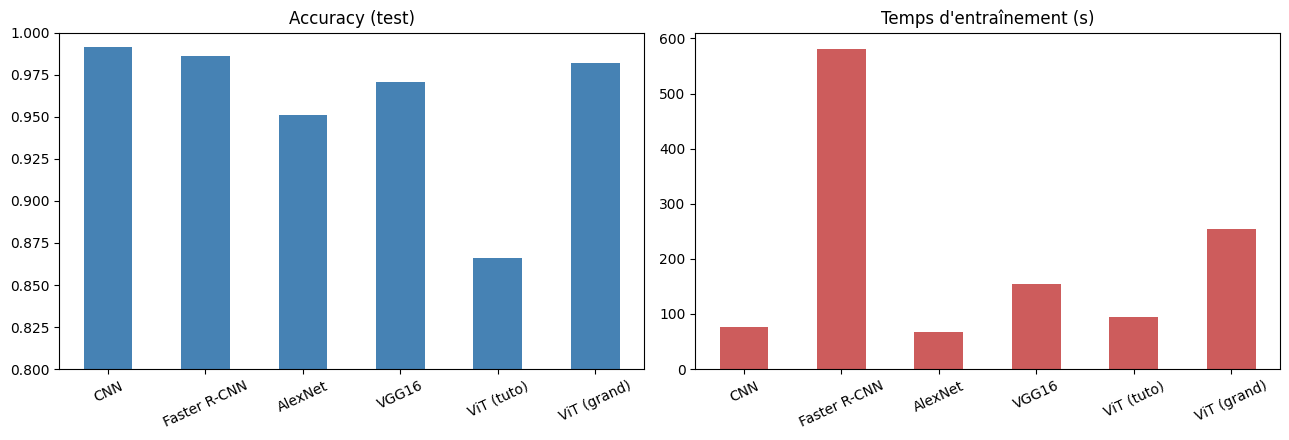

In [ ]:
# Graphiques
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
df["Accuracy"].plot.bar(ax=ax[0], ylim=(0.8, 1.0), title="Accuracy (test)", color="steelblue")
df["Temps (s)"].plot.bar(ax=ax[1], title="Temps d'entraînement (s)", color="indianred")
for a in ax:
    a.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig("comparaison_atelier2.png", dpi=150)
plt.show()

**Comparaison avec la partie 1 et conclusion générale**

Classement par accuracy : CNN 99,18 % > Faster R-CNN 98,65 % > ViT (grand) 98,20 % > VGG16 97,10 % > AlexNet 95,12 % > ViT (tuto) 86,60 %.

- Le ViT grand dépasse VGG16 et AlexNet fine-tunés, mais reste environ 1 point sous le CNN, tout en étant environ 3,3 fois plus lent.
- Un CNN intègre des a priori adaptés aux images (filtres locaux, partage des poids, chapitre 4). Un ViT doit apprendre ces régularités avec l'attention (chapitre 6) : il est surtout avantageux avec de grands modèles et beaucoup de données.
- Les temps du ViT sont gonflés par l'implémentation pédagogique du tutoriel (boucle sur les têtes d'attention).
- **Conclusion** : sur MNIST, le CNN entraîné de zéro offre le meilleur compromis précision / temps / taille.
- **Limites** : une seule exécution par modèle ; nombre d'epochs et jeux de données différents selon les modèles (Faster R-CNN : 10 000 / 2 000 images) ; optimiseurs non harmonisés ; loss de Faster R-CNN non comparable.

**Synthèse personnelle**

Cet atelier m'a permis de prendre en main PyTorch sur GPU : charger les données (Dataset, DataLoader), définir un réseau (nn.Module), écrire la boucle d'entraînement (zero_grad, backward, step) et évaluer les modèles avec l'accuracy, le F1-score, la loss et le temps.

J'ai construit un CNN pour MNIST et vérifié à la main, avec les formules du cours, les dimensions et le nombre de paramètres (421 642). C'est lui qui a obtenu le meilleur résultat : 99,18 %.

J'ai compris que Faster R-CNN est un détecteur d'objets, trop lourd pour classer un seul chiffre (98,65 %, environ 7,6 fois plus lent), et que le transfert d'apprentissage avec VGG16 (97,10 %) et AlexNet (95,12 %) est surtout utile quand les données sont peu nombreuses ou proches d'ImageNet.

En construisant le Vision Transformer étape par étape (patchs, token de classe, encodage positionnel, attention multi-têtes), j'ai vu comment l'attention du cours s'applique aux images. Ses performances dépendent fortement de sa taille : 86,60 % avec 1 642 paramètres, 98,20 % avec environ 148 000.

Enfin, j'ai appris à comparer des modèles honnêtement, en tenant compte des différences de données, d'epochs et de définition de la loss.